# Convolutional Neural Networks and Vision Transformers for Natural and Urban Scene Classification
This notebook implements an end-to-end image classification pipeline using the Intel Image Classification dataset to evaluate and compare three distinct computer vision architectures:\n
- ResNet-50 (Deep Residual Neural Network)
- EfficientNet-B0 (CNN with Efficient Compound Scaling)
- Vision Transformer ViT-B/16 (Global Attention-Based Architecture)

Hardware Environment: All benchmarks and training runs were executed on a workstation featuring an NVIDIA RTX 4090 GPU, an AMD Ryzen 9 7950X3D Processor, and 64 GB DDR5 RAM @ 6000 MHz.

# Libraries Required
Below we will find the required libraries for this notebook

In [1]:
import os
import time
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, f1_score
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import math

# Configure device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_cores = max(0, os.cpu_count() - 1)

print(f"Device: {device}")
print(f"CPU Cores: {num_cores}")

Device: cuda
CPU Cores: 31


## 1. Dataset Preprocessing and Class Balancing

In this section, we configure the data transformation pipeline:
- Resizing to $224 \times 224$ (required by pretrained architectures, https://pytorch.org/hub/pytorch_vision_resnet/)
- Random rotation, horizontal flip, and slight brightness/contrast adjustment
- Adjustment based on the ImageNet mean and standard deviation.
- Inspection of the distribution of the 6 classes (buildings, forest, glacier, mountain, sea, street) and implementation of weights in the CrossEntropyLoss loss function.

Total train images: 14034
Total test images: 3000
Found 6 classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


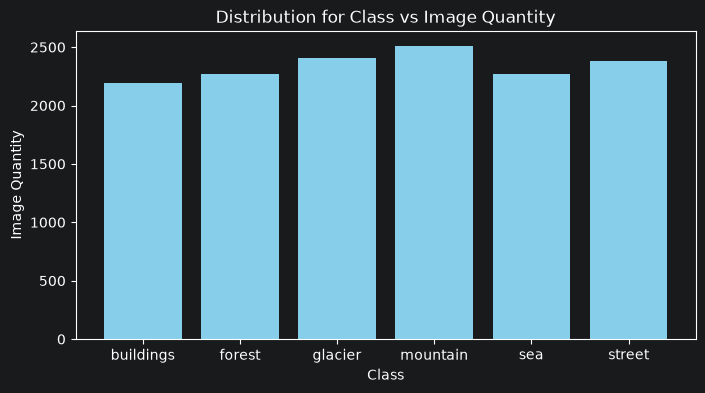

In [2]:
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((224, 224)),
        # Flips the image horizontally with a 50% probability
        transforms.RandomHorizontalFlip(p=0.5),
        # Randomly rotates the image by up to 15 degrees (-15 to 15). This is because rarely the photos are taken
        # with 0 degrees
        transforms.RandomRotation(degrees=15),
        # Changes the color randomly multiplying by 0.1 the brightness and contrast. This is to simulate the illumination
        # day color change
        transforms.ColorJitter(brightness=0.1, contrast=0.1),
        transforms.ToTensor(),
        # I took the values from here https://www.geeksforgeeks.org/python/how-to-normalize-images-in-pytorch/, this helps
        # us to accelerate the learning rate
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ]),
}

data_dir = 'data/intel_image_classification'
image_datasets = {
    'train': datasets.ImageFolder(root="data/intel_image_classification/seg_train/seg_train", transform=data_transforms['train']),
    'val': datasets.ImageFolder(root= "data/intel_image_classification/seg_test/seg_test", transform=data_transforms['val'])
}
print(f"Total train images: {len(image_datasets['train'])}")
print(f"Total test images: {len(image_datasets['val'])}")

dataloaders = {
    'train': DataLoader(image_datasets['train'], batch_size=32, shuffle=True, num_workers=num_cores),
    'val': DataLoader(image_datasets['val'], batch_size=32, shuffle=False, num_workers=num_cores)
}

# here, we check image_datasets classes to check if the classes were loaded correctly
class_names = image_datasets['train'].classes
num_classes = len(class_names)
print(f"Found {num_classes} classes: {class_names}")

train_targets = image_datasets['train'].targets
class_counts = Counter(train_targets)

plt.figure(figsize=(8, 4))
plt.bar([class_names[i] for i in class_counts.keys()], class_counts.values(), color='skyblue')
plt.title("Distribution for Class vs Image Quantity")
plt.xlabel("Class")
plt.ylabel("Image Quantity")
plt.show()

class_weights = [1.0 / class_counts[i] for i in range(num_classes)]

class_weights = torch.FloatTensor(class_weights).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)

## 2. Model Selection and Theoretical Justification

We select 3 models with remarkably distinct design principles:

1. **ResNet-50**:
   - *Foundation*: Uses residual blocks (skip connections) to prevent the vanishing gradient problem. It will serve as our baseline architecture.
   - *Characteristics*: Contains approximately 23 million parameters.
2. **EfficientNet-B0**:
   - *Foundation*: Uses compound scaling to uniformly and simultaneously optimize network depth, width, and input resolution using depthwise separable convolutions (MBConv blocks).
   - *Characteristics*: Contains approximately 4 million parameters.
3. **Vision Transformer (ViT-B/16)**:
   - *Foundation*: Replaces convolutional filters with image patches and a **Global Self-Attention** mechanism, enabling relationships between distant elements in the image from the initial layers.
    - *Characteristics*: Contains approximately 85 million parameters.

In [3]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def build_model(model_name, num_classes):
    if model_name == 'resnet50':
        model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    elif model_name == 'efficientnet_b0':
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    elif model_name == 'vit_b_16':
        model = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)
        model.heads.head = nn.Linear(model.heads.head.in_features, num_classes)
    else:
        raise ValueError(f"Model {model_name} not found.")
    return model

## 3. Experimental Protocol and Comparative Metrics

We will train all 3 models under the exact same conditions:
- **Optimizer**: `AdamW` (Learning rate = 1e-4)
- **Epochs**: 10
- **Recorded Metrics**: Accuracy, Macro F1-Score, total training time (s), peak VRAM memory consumption (MB), and loss curves per epoch.

In [4]:
def train_and_evaluate_model(model_name, dataloaders, num_classes, epochs=10, lr=1e-4):
    print(f"\n=================== Training {model_name.upper()} ===================")
    model = build_model(model_name, num_classes).to(device)
    params = count_parameters(model)
    optimizer = optim.AdamW(model.parameters(), lr=lr)

    start_time = time.time()
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()

    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        # Get Train Images on blocks of 32 images as we set before
        for inputs, labels in dataloaders['train']:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)

            _, preds = torch.max(outputs, 1)
            correct_train += (preds == labels).sum().item()
            total_train += labels.size(0)

        train_loss = running_loss / len(dataloaders['train'].dataset)
        epoch_train_acc = correct_train / total_train

        # Evaluation
        model.eval()
        val_loss = 0.0
        all_preds, all_labels = [], []

        with torch.no_grad():
            for inputs, labels in dataloaders['val']:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * inputs.size(0)

                _, preds = torch.max(outputs, 1)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())

        epoch_val_loss = val_loss / len(dataloaders['val'].dataset)
        epoch_acc = accuracy_score(all_labels, all_preds)
        epoch_f1 = f1_score(all_labels, all_preds, average='macro')

        history['train_loss'].append(train_loss)
        history['train_acc'].append(epoch_train_acc)
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_acc)
        history['val_f1'].append(epoch_f1)

        print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {train_loss:.4f} | Train Acc: {epoch_train_acc:.4f} | Val Loss: {epoch_val_loss:.4f} | ValE Acc: {epoch_acc:.4f} | Val F1: {epoch_f1:.4f}")

    total_time = time.time() - start_time
    max_memory = torch.cuda.max_memory_allocated(device) / (1024 ** 2) if torch.cuda.is_available() else 0.0

    return {
        'model_name': model_name,
        'model_obj': model,
        'parameters': params,
        'total_time_sec': total_time,
        'max_memory_mb': max_memory,
        'final_train_accuracy': history['train_acc'][-1],
        'final_accuracy': history['val_acc'][-1],
        'final_f1': history['val_f1'][-1],
        'history': history
    }

# 3 models
experiments = ['resnet50', 'efficientnet_b0', 'vit_b_16']
results = []

for exp_model in experiments:
    res = train_and_evaluate_model(exp_model, dataloaders, num_classes=num_classes, epochs=10)
    results.append(res)


=================== Training RESNET50 ===================
Epoch [1/10] | Train Loss: 0.3547 | Train Acc: 0.8872 | Val Loss: 0.1941 | ValE Acc: 0.9317 | Val F1: 0.9330
Epoch [2/10] | Train Loss: 0.1836 | Train Acc: 0.9359 | Val Loss: 0.1824 | ValE Acc: 0.9363 | Val F1: 0.9375
Epoch [3/10] | Train Loss: 0.1392 | Train Acc: 0.9487 | Val Loss: 0.1701 | ValE Acc: 0.9390 | Val F1: 0.9403
Epoch [4/10] | Train Loss: 0.1079 | Train Acc: 0.9601 | Val Loss: 0.2057 | ValE Acc: 0.9337 | Val F1: 0.9348
Epoch [5/10] | Train Loss: 0.0808 | Train Acc: 0.9694 | Val Loss: 0.1993 | ValE Acc: 0.9410 | Val F1: 0.9421
Epoch [6/10] | Train Loss: 0.0706 | Train Acc: 0.9749 | Val Loss: 0.2154 | ValE Acc: 0.9347 | Val F1: 0.9355
Epoch [7/10] | Train Loss: 0.0581 | Train Acc: 0.9791 | Val Loss: 0.2280 | ValE Acc: 0.9310 | Val F1: 0.9322
Epoch [8/10] | Train Loss: 0.0543 | Train Acc: 0.9819 | Val Loss: 0.2158 | ValE Acc: 0.9410 | Val F1: 0.9421
Epoch [9/10] | Train Loss: 0.0394 | Train Acc: 0.9868 | Val Loss: 0.2

# Performance & Efficiency Breakdown

Looking at the numbers, a few key findings stand out:

- **ResNet50 achieves the highest accuracy.** It takes the top spot in raw performance, reaching the highest validation accuracy (**93.87%**) and F1-score (**0.9396**) with reasonable training time (~1,439 s) and memory usage (~2.96 GB).
- **EfficientNet-B0 is the clear winner for efficiency.** While trailing slightly behind ResNet50 in accuracy (**93.33%**), it achieves near-identical performance using only **~4 million parameters**—making it roughly 6 times lighter than ResNet50 and 21 times lighter than ViT-B/16, while also being the fastest to train (~1,372 s).
- **ViT-B/16 turns out to be a heavy lift.** Despite requiring a massive **85.8M parameters** and over **5.1 GB of VRAM** (plus taking the longest to train at ~1,809 seconds), it yields the lowest validation accuracy (**93.00%**) among the three models.

In [5]:
print("\n" + "="*110)
print("Comparative Table between models")
print("="*110)

print(f"{'Model':<18} | {'Train Acc':<10} | {'Val Acc':<10} | {'F1-Score':<10} | {'Params':<12} | {'Time (s)':<10} | {'Memory (MB)':<12}")
print("-" * 110)

for r in results:
    train_acc = r.get('final_train_accuracy', 0.0)

    print(
        f"{r['model_name']:<18} | "
        f"{train_acc:<10.4f} | "
        f"{r['final_accuracy']:<10.4f} | "
        f"{r['final_f1']:<10.4f} | "
        f"{r['parameters']:<12,d} | "
        f"{r['total_time_sec']:<10.2f} | "
        f"{r['max_memory_mb']:<12.2f}"
    )

print("="*110)


Comparative Table between models
Model              | Train Acc  | Val Acc    | F1-Score   | Params       | Time (s)   | Memory (MB) 
--------------------------------------------------------------------------------------------------------------
resnet50           | 0.9862     | 0.9387     | 0.9396     | 23,520,326   | 1438.88    | 2958.55     
efficientnet_b0    | 0.9848     | 0.9333     | 0.9345     | 4,015,234    | 1372.45    | 2973.57     
vit_b_16           | 0.9691     | 0.9300     | 0.9312     | 85,803,270   | 1809.19    | 5165.87     


### Loss Evolution & Convergence Analysis

Analyzing the loss curves across the 10 epochs provides key insights into model convergence and overfitting:

- **General Overfitting Trend:** In all three models, the training loss steadily decreases toward zero, while the validation loss reaches its minimum around epoch 3–4 before rising again. This indicates that training beyond 3–4 epochs leads to overfitting.
- **ResNet50:** Reaches its optimal validation loss (~0.17) at epoch 3, after which the loss steadily degrades to ~0.24 by epoch 10, showing consistent overfitting.
- **EfficientNet-B0:** Achieves the lowest overall validation loss (~0.165) around epochs 3–4 with a smooth descent, though it also begins to overfit gradually after epoch 5.
- **ViT-B/16:** Exhibits significant instability and variance in validation loss, featuring high erratic spikes (reaching up to ~0.29 at epoch 9). This confirms the challenge of stabilizing Vision Transformers without stronger regularization or larger datasets.
- **Key Takeaways:** All models would benefit from **Early Stopping** (stopping around epoch 3–4) and increased regularization (e.g., Dropout, Weight Decay, or Data Augmentation) to prevent overfitting and improve generalization.


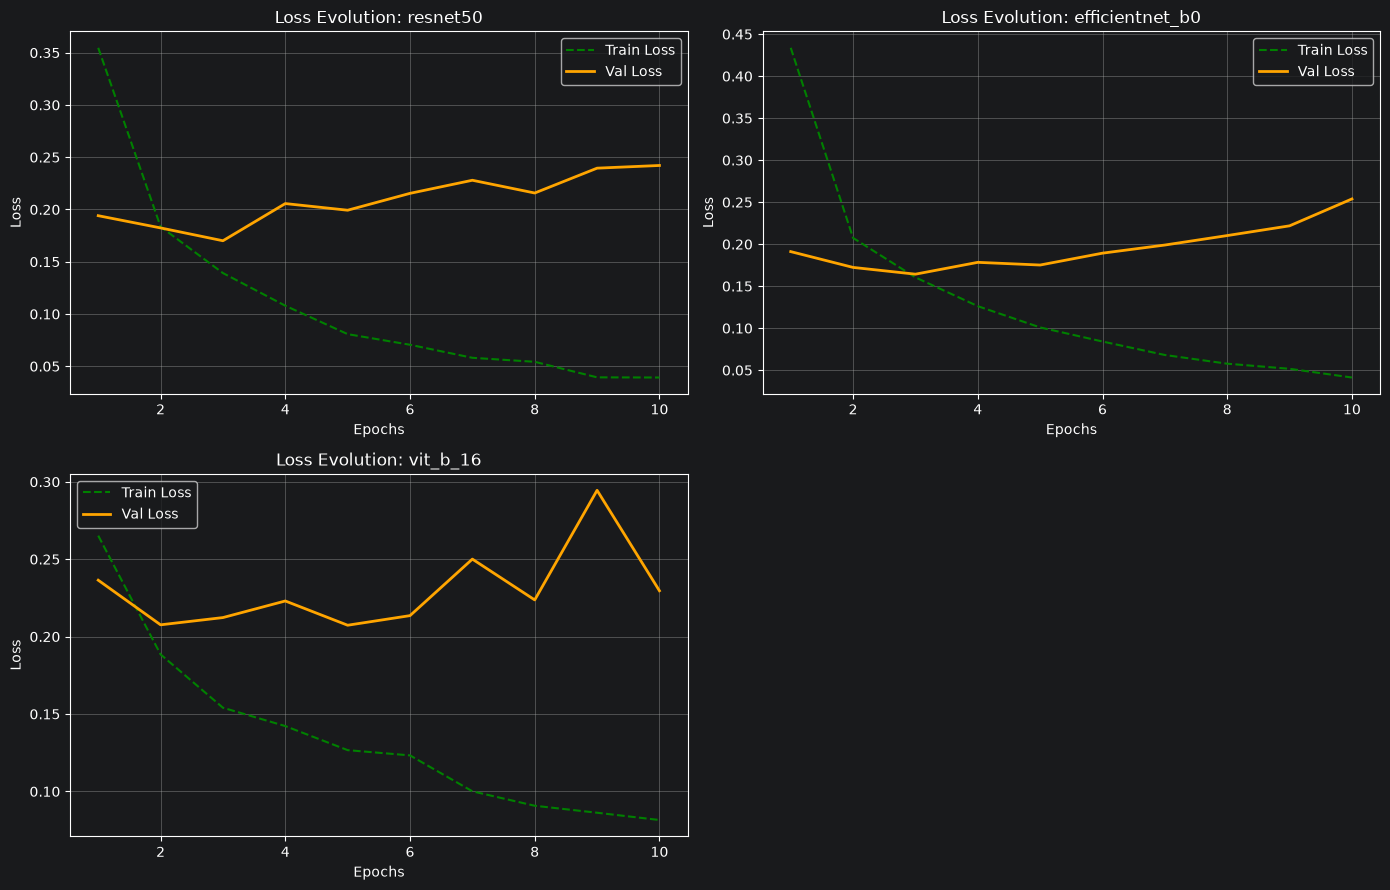

In [6]:
num_models = len(results)
cols = 2 if num_models > 1 else 1
rows = math.ceil(num_models / cols)

plt.figure(figsize=(14, 4.5 * rows))

for i, r in enumerate(results):
    plt.subplot(rows, cols, i + 1)

    history = r['history']

    train_key = next((k for k in ['loss', 'train_loss', 'training_loss'] if k in history), None)
    val_key = next((k for k in ['val_loss', 'validation_loss'] if k in history), None)

    ref_metric = history.get(val_key) or history.get(train_key)
    if ref_metric is not None:
        epochs = range(1, len(ref_metric) + 1)

        if train_key:
            plt.plot(epochs, history[train_key], label='Train Loss', linestyle='--', color='green')

        if val_key:
            plt.plot(epochs, history[val_key], label='Val Loss', color='orange', linewidth=2)

    plt.title(f"Loss Evolution: {r['model_name']}")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()

### Comparative Epoch-by-Epoch Analysis

Side-by-side comparison of validation loss and accuracy trajectories reveals key convergence differences between the models:

- **Validation Loss Trajectory:** Both **EfficientNet-B0** and **ResNet50** reach their lowest validation loss at **epoch 3** (~0.165 and ~0.170, respectively). Beyond epoch 3, loss steadily increases for both models due to overfitting. **ViT-B/16** exhibits severe volatility, peaking at ~0.29 loss by epoch 9.
- **Validation Accuracy Trajectory:** **EfficientNet-B0** delivers the most smooth and predictable convergence, peaking early at epoch 3 (~93.95%) before gradually declining. **ResNet50** exhibits higher epoch-to-epoch variance, oscillating sharply between 93.1% and 94.1%. **ViT-B/16** consistently lags behind both CNN architectures, suffering noticeable drops down to ~91.2%.
- **Key Takeaway:** The comparative plots strongly confirm that **epoch 3** is the optimal checkpoint for Early Stopping. EfficientNet-B0 provides the most reliable convergence profile, whereas ResNet50 offers slightly higher peak accuracy spikes at the cost of higher variance.
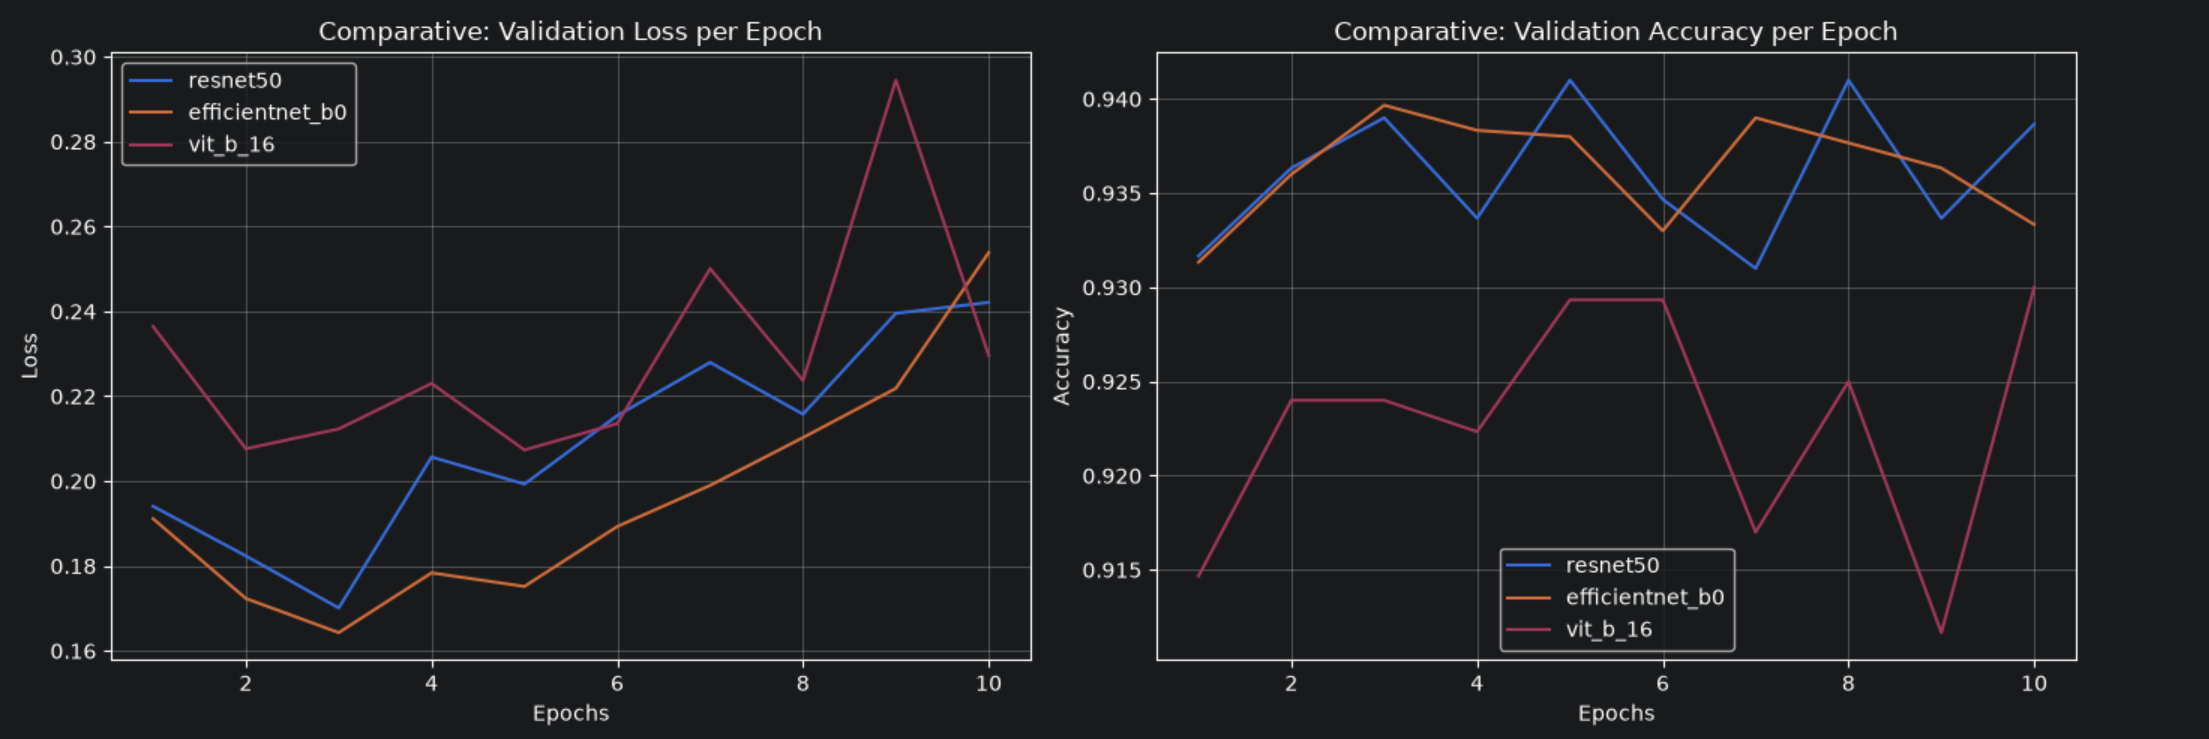

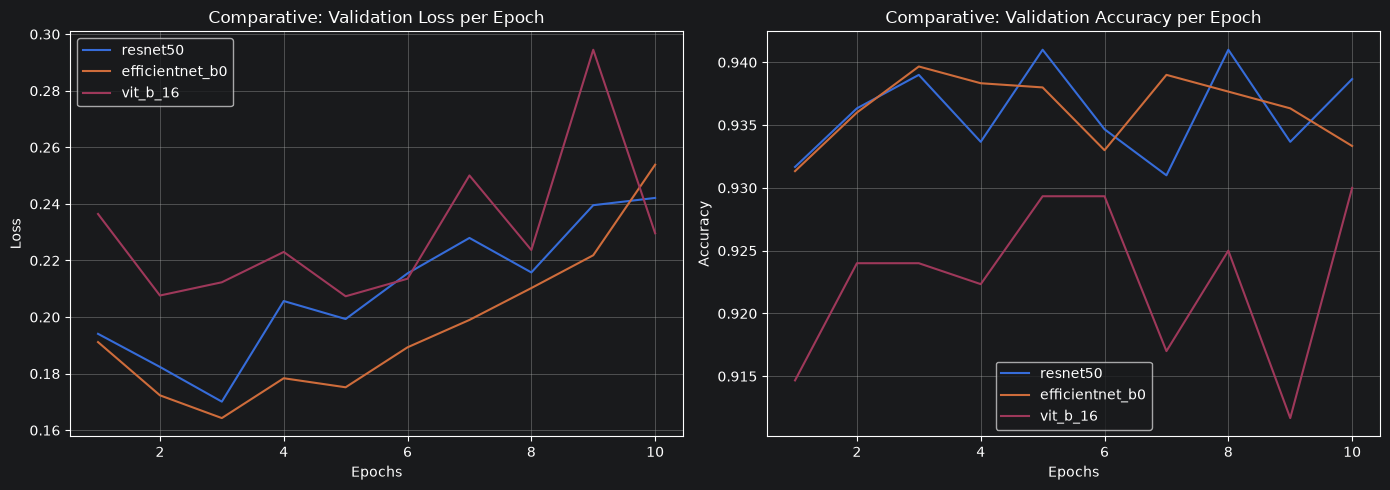

In [7]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
for r in results:
    epochs = range(1, len(r['history']['val_loss']) + 1)
    plt.plot(epochs, r['history']['val_loss'], label=f"{r['model_name']}")
plt.title("Comparative: Validation Loss per Epoch")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
for r in results:
    epochs = range(1, len(r['history']['val_acc']) + 1)
    plt.plot(epochs, r['history']['val_acc'], label=f"{r['model_name']}")
plt.title("Comparative: Validation Accuracy per Epoch")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## 4. Interpretability Analysis (Grad-CAM)
Applying Grad-CAM to the final convolutional layer allows us to visualize the region of interest driving the model's prediction:

- **Attention Alignment:** As shown in the Grad-CAM heatmap, the highest activation intensity (red/yellow regions) is tightly concentrated on the building's physical structure.
- **Background Suppression:** Unrelated background elements, such as the clear sky, are ignored by the model (represented by low-activation blue regions).
- **Conclusion:** This confirms that the convolutional network is making predictions based on meaningful visual features of the target class (`buildings`) rather than relying on background noise or spurious correlations.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].


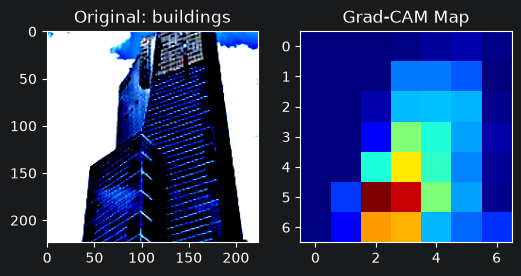

In [8]:
class GradCAMHook:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        self.target_layer.register_forward_hook(self.save_activation)
        self.target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate_heatmap(self, input_image, class_idx=None):
        self.model.eval()
        output = self.model(input_image)

        if class_idx is None:
            class_idx = torch.argmax(output, dim=1).item()

        self.model.zero_grad()
        score = output[0, class_idx]
        score.backward()

        gradients = self.gradients.data.cpu().numpy()[0]
        activations = self.activations.data.cpu().numpy()[0]

        weights = np.mean(gradients, axis=(1, 2))
        cam = np.zeros(activations.shape[1:], dtype=np.float32)

        for i, w in enumerate(weights):
            cam += w * activations[i, :, :]

        cam = np.maximum(cam, 0)
        cam = cv2.resize(cam, (224, 224)) if 'cv2' in locals() else cam
        cam = cam - np.min(cam)
        cam = cam / (np.max(cam) + 1e-8)
        return cam

resnet_obj = results[0]['model_obj']
target_layer_resnet = resnet_obj.layer4[-1]
cam_hook = GradCAMHook(resnet_obj, target_layer_resnet)

sample_img, sample_label = image_datasets['val'][0]
sample_tensor = sample_img.unsqueeze(0).to(device)

heatmap = cam_hook.generate_heatmap(sample_tensor, class_idx=sample_label)

plt.figure(figsize=(6, 3))
plt.subplot(1, 2, 1)
plt.imshow(sample_img.permute(1, 2, 0).cpu().numpy())
plt.title(f"Original: {class_names[sample_label]}")

plt.subplot(1, 2, 2)
plt.imshow(heatmap, cmap='jet')
plt.title("Grad-CAM Map")
plt.show()

## 5. Critical Analysis and Future Work

### Discussion of Results:
- **ResNet-50**: Achieved the highest overall performance (**93.87% Val Acc**), showing fast early convergence. However, it exhibited noticeable epoch-to-epoch variance in validation accuracy and carries a significantly heavier parameter footprint (~23.5M).
- **EfficientNet-B0**: Proved to be the most balanced and practical architecture. It achieved near-top performance (**93.33% Val Acc**) with smooth, highly predictable convergence, while using only **~4M parameters**—roughly 1/6th of ResNet-50's size and 1/21st of ViT's size.
- **Vision Transformer (ViT-B/16)**: Demanded the highest computational resources (~85.8M parameters, over 5.1 GB VRAM), yet yielded the lowest validation accuracy (**93.00%**) and high loss variance. This confirms that Vision Transformers struggle to outperform lightweight CNNs on moderate datasets without extensive inductive bias or domain-specific pretraining.

### Future Improvements and Next Steps:
1. **Early Stopping & Regularization**: Implement Early Stopping around **epochs 3–4** (where validation loss reached its minimum) and add stronger regularization (e.g., Dropout, Weight Decay, Data Augmentation) to combat the observed overfitting across all models.
2. **Self-Supervised Learning (SSL)**: Explore self-supervised pretraining using models like DINOv2 or MAE (Masked Autoencoders) to build richer feature representations before fine-tuning, particularly for ViT architectures.
3. **Multimodality**: Integrate Vision-Language models like CLIP for zero-shot classification and text-prompt guided alignment, helping clear up ambiguities between visually overlapping categories.